<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/07_Ransomware_Detection/QSVM_RansomwareDetection_Kaur2024.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# QSVM, Pegasos QSVM and VQC for ransomware / malware detection: Kaur et al. 2024, step by step

**Paper.** Manvi Kaur, Kriti Jain, Ananya Singla, Karuna Kadian, *"Quantum Exploration in Ransomware Detection with Conventional Machine Learning Approaches"*, 2024 IEEE International Conference on Contemporary Computing and Communications (InC4), IEEE. DOI: [10.1109/InC460750.2024.10649082](https://doi.org/10.1109/InC460750.2024.10649082).

**What this notebook does.** The paper compares three classical classifiers (SVM, Decision Tree, XGBoost) with three Qiskit quantum models (a fidelity-kernel **QSVM**, **Pegasos QSVM** and a **VQC**) on a table of Windows executable-header features with 138,047 files. The notebook rebuilds that comparison from the paper's description:

1. downloads the public copy of that table (138,047 rows x 57 columns, 41,323 legitimate and 96,724 malicious files, exactly the counts of the paper's Table II),
2. checks the paper's data statements (including the odd "first 500 entries" statement, which turns out to be impossible to follow literally),
3. draws a stratified sample of 500 files, splits it, and applies the paper's preprocessing steps (VIF and Information Value feature selection, SMOTE, PCA to one component per qubit), all fitted on the training split only,
4. trains the three classical models and the three quantum models (Qiskit 2.x, `qiskit-machine-learning`), measuring accuracy, precision, recall, F1 and train / test time,
5. repeats everything over several random seeds, because a 100-file test set makes single-run numbers noisy,
6. puts the paper's Tables III and IV next to the notebook's numbers, with a verdict per claim, and closes with a critical reading and exercises.

**How to run.** Open in Google Colab, choose a **CPU runtime**, and use *Runtime -> Run all*. With `FAST_MODE = True` the whole notebook finishes in under 10 minutes; `FAST_MODE = False` uses the paper-like budgets (Pegasos 1000 steps, VQC with 100 COBYLA iterations, more seeds) and takes roughly an hour on a laptop CPU. No quantum computer is needed: every circuit runs on an exact state-vector simulator.

**What you get at the end.** A results table (mean +/- std over seeds) for the six models, confusion matrices, the paper's Fig. 1 (time) and Fig. 2 (accuracy / precision / recall / F1) redrawn, extra diagnostics (qubit sweep, unscaled features, all-feature and full-data classical references), and a side-by-side comparison with the paper.

## The paper in one page

* **Problem.** Compare classical machine learning with quantum machine learning (QML) for ransomware detection, including the training and testing time.
* **Decision.** Binary: legitimate versus malicious executable.
* **Models.** Classical: SVM (RBF kernel), Decision Tree (Gini index), XGBoost. Quantum: "Quantum-enhanced SVM" (QSVM, a fidelity quantum kernel inside an SVM, `QSVC`), Pegasos QSVM (`PegasosQSVC`, the Pegasos sub-gradient algorithm on the same kind of kernel) and a VQC (feature map + ansatz + classical optimiser). The qubit count, feature map, ansatz, optimiser, `C`, Pegasos steps and every other hyper-parameter are **not stated**.
* **Data.** "Ransomware database" of 138,047 Windows binaries with 57 columns; Table II lists 41,323 "Ransomware" and 96,724 "Goodware"; the text says 70 % ransomware and 30 % valid. Two identity columns (`Name`, `md5`) are dropped, leaving 54 features plus the target `legitimate`. The paper says "the first 500 entries were considered for ease of computation".
* **Preprocessing.** SMOTE oversampling of the minority class, Variance Inflation Factor (VIF) to remove collinear features, Information Value (IV) and Weight of Evidence (WoE) to rank features, and PCA to reduce the dimension for the simulator.
* **Environment.** Python 3, Jupyter in VS Code, 12.1 / 15.9 GB RAM. All quantum models are simulated.
* **Claims that can be checked.**
  * Table III (accuracy / precision / recall / F1): SVM 80 / 82 / 80 / 81, Decision Tree 88 / 88 / 88 / 88, XGBoost 88 / 88 / 88 / 88, QSVM 68 / 74 / 68 / 70, Pegasos QSVM 75 / 72 / 75 / 71, VQC 57 / 63 / 57 / 59 (percent). Precision, recall and F1 are class-weighted averages (recall equals accuracy in every column).
  * Table IV (seconds, train / test): SVM 0.023 / 0.038, Decision Tree 0.023 / 0.025, XGBoost 0.358 / 0.024, QSVM 1088.2 / 436.2, Pegasos QSVM 3481.6 / 400.9, VQC 705.9 / 1.1.
  * Qualitative: Decision Tree and XGBoost beat SVM; Pegasos QSVM is the best quantum model; VQC is the worst; the quantum models "did not outperform" the classical ones; quantum models are far slower; the text also says QSVM beats the classical SVM in precision (which contradicts Table III).

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Dataset | "Ransomware database", 138,047 x 57, Table II counts | Public copy of the same table (`MalwareData.csv.gz`, `\|`-separated) from the O'Reilly Japan *ml-security-jp* repository, served by jsDelivr with a GitHub raw fallback. Counts match Table II exactly. The file is a **generic PE-header malware set** (VirusShare malware versus legitimate binaries), not a ransomware-only set |
| Class names | Table II: 41,323 "Ransomware", 96,724 "Goodware" | In the file `legitimate = 1` for 41,323 files and `0` for 96,724. Table II has the two names swapped (the text says 70 % malicious, which agrees with the file). `# CHOICE:` label `y = 1` = malicious so that "attack" is the positive class |
| "First 500 entries" | First 500 rows of the file | The file is sorted by class: its first 500 rows are **all legitimate**, so no classifier can be trained on them. `# CHOICE:` a stratified random sample of 500 files (keeps the 30 / 70 class ratio) |
| Split | Not stated | `# CHOICE:` stratified 80 / 20 (400 train / 100 test) |
| Identity columns | `Name`, `md5` dropped | Same; 54 features remain |
| Feature selection | VIF, then IV / WoE (thresholds not stated) | `# CHOICE:` iterative VIF removal until all VIF <= 10, then keep features with IV >= 0.02 (at least as many as qubits). Fitted on the training split only |
| Heavy tails | Not stated | `# CHOICE:` signed `log1p` of every feature before standardising (PE sizes span many orders of magnitude). Section 7 repeats a run without it |
| SMOTE | Applied, parameters not stated | `imblearn` SMOTE (k = 5), **training split only** |
| PCA / qubits | PCA, number not stated | `# CHOICE:` 4 components = 4 qubits (also swept 2 to 8); angles scaled to [0, pi] with a min-max scaler fitted on the training set, test angles clipped |
| QSVM | Fidelity quantum kernel (`QSVC`) | `QSVC` with `FidelityStatevectorKernel`; `# CHOICE:` `zz_feature_map(reps=2, linear)`, `C = 1` |
| Pegasos QSVM | `PegasosQSVC` | `PegasosQSVC`, same kernel; `# CHOICE:` `C = 1000` and `num_steps` 1000 (200 in fast mode) |
| VQC | Feature map + ansatz + optimiser | `VQC` with the same ZZ feature map, `real_amplitudes(reps=3)`, COBYLA (`maxiter` 100, 15 in fast mode), `StatevectorSampler` (1024 shots) |
| Classical models | SVM (RBF), Decision Tree (Gini), XGBoost | `SVC(rbf)` defaults, `DecisionTreeClassifier(gini)`, `XGBClassifier` defaults. `# CHOICE:` main table uses the **same 4 PCA inputs as the quantum models**; the 54-feature versions are in Section 7 |
| Metrics | Accuracy; precision / recall / F1 (class-weighted, since recall = accuracy) | Same weighted averages, plus malicious-class precision / recall / F1 and confusion matrices |
| Repetitions | One run | `# CHOICE:` several seeds (each seed redraws the 500-file sample and the split), mean +/- std |

In [1]:
# Install pinned versions tested for this notebook (Colab ships numpy, pandas, scikit-learn, matplotlib).
# The guard skips the install on a machine where the packages are already importable.
import sys, importlib.util
IN_COLAB = "google.colab" in sys.modules
need = [m for m in ("qiskit", "qiskit_machine_learning", "qiskit_aer", "xgboost", "imblearn", "pylatexenc")
        if importlib.util.find_spec(m) is None]
if IN_COLAB or need:
    %pip -q install "qiskit==2.5.2" "qiskit-machine-learning==0.9.1" "qiskit-aer==0.17.2" "xgboost" "imbalanced-learn" pylatexenc
    print("Installed pinned packages. If Colab asks you to restart the session, restart and run all cells again.")
else:
    print("All required packages are already available; nothing to install.")

All required packages are already available; nothing to install.


In [2]:
# ---------------- configuration: every tunable constant lives here ----------------
FAST_MODE = False           # True: under 10 minutes (class demo).  False: paper-like budgets, roughly an hour on a laptop CPU.
SEED = 42                   # master seed

N_SAMPLE   = 500            # paper: "the first 500 entries" (impossible literally, see Section 1) -> stratified random sample
TEST_SIZE  = 0.20           # CHOICE: paper does not give the split
N_QUBITS   = 4              # CHOICE: PCA components = qubits (paper does not state it)
FM_REPS    = 2              # CHOICE: ZZ feature map repetitions
VIF_MAX    = 10.0           # CHOICE: classical VIF cut-off
IV_MIN     = 0.02           # CHOICE: Information Value below 0.02 is conventionally "not predictive"
LOG_TRANSFORM = True        # CHOICE: signed log1p before standardising
QSVC_C     = 1.0            # CHOICE
PEGASOS_C  = 1000.0         # CHOICE (qiskit-machine-learning default regularisation for Pegasos is 1.0; 1000 is the value of the Qiskit tutorial)
SHOTS      = 1024           # VQC sampler shots

if FAST_MODE:
    SEEDS        = [42, 43, 44]       # seeds for the cheap models (SVM, DT, XGB, QSVM)
    SLOW_SEEDS   = [42]               # seeds for Pegasos QSVM and VQC
    PEGASOS_STEPS = 200
    VQC_MAXITER  = 15
    SWEEP_QUBITS = [2, 4, 6]
    SWEEP_SEEDS  = SEEDS[:2]
else:
    SEEDS        = [42, 43, 44, 45, 46]
    SLOW_SEEDS   = [42, 43, 44]
    PEGASOS_STEPS = 1000
    VQC_MAXITER  = 100
    SWEEP_QUBITS = [2, 4, 6, 8]
    SWEEP_SEEDS  = SEEDS

DATA_DIR  = "malware_pe_data"   # cache folder for the downloaded file
DATA_PATH = None                # or the path of an uploaded MalwareData.csv.gz / MalwareData.csv
IBM_TOKEN = ""                  # not used: this paper needs no quantum hardware (kept for the repository convention)
print(f"FAST_MODE={FAST_MODE}  seeds={SEEDS}  slow-model seeds={SLOW_SEEDS}  pegasos steps={PEGASOS_STEPS}  vqc maxiter={VQC_MAXITER}")

FAST_MODE=False  seeds=[42, 43, 44, 45, 46]  slow-model seeds=[42, 43, 44]  pegasos steps=1000  vqc maxiter=100


In [3]:
import os, time, warnings, random
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
warnings.filterwarnings("ignore")

import sklearn, qiskit, qiskit_machine_learning, xgboost, imblearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, ConfusionMatrixDisplay
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE

from qiskit.circuit.library import zz_feature_map, real_amplitudes
from qiskit.primitives import StatevectorSampler
from qiskit.quantum_info import Statevector
from qiskit_machine_learning.kernels import FidelityStatevectorKernel
from qiskit_machine_learning.algorithms import QSVC, PegasosQSVC, VQC
from qiskit_machine_learning.optimizers import COBYLA
from qiskit_machine_learning.utils import algorithm_globals

random.seed(SEED); np.random.seed(SEED); algorithm_globals.random_seed = SEED
rng = np.random.default_rng(SEED)
print("qiskit", qiskit.__version__, "| qiskit-machine-learning", qiskit_machine_learning.__version__,
      "| scikit-learn", sklearn.__version__, "| xgboost", xgboost.__version__, "| imbalanced-learn", imblearn.__version__,
      "| numpy", np.__version__, "| pandas", pd.__version__)

qiskit 2.5.2 | qiskit-machine-learning 0.9.1 | scikit-learn 1.9.1 | xgboost 3.4.1 | imbalanced-learn 0.14.2 | numpy 2.5.4 | pandas 3.0.6


## 1. Data: the 138,047-file PE-header table

The paper's dataset has 138,047 samples and 57 columns: two identity columns (`Name`, `md5`), 54 numeric header and section features, and the target `legitimate`. The public file `MalwareData.csv.gz` (about 12 MB, `|`-separated) has exactly this shape and the class counts of Table II. It is cached in `DATA_DIR`. If both mirrors fail, upload the file and set `DATA_PATH`.

We define `y = 1` for **malicious** and `y = 0` for legitimate, so that the attack class is the positive class everywhere (note that the file's own `legitimate` flag is the opposite).

In [4]:
import requests
URLS = [
    "https://cdn.jsdelivr.net/gh/oreilly-japan/ml-security-jp@master/ch03/MalwareData.csv.gz",          # CDN, fast
    "https://raw.githubusercontent.com/oreilly-japan/ml-security-jp/master/ch03/MalwareData.csv.gz",    # same repo, GitHub raw (slow)
]
os.makedirs(DATA_DIR, exist_ok=True)
data_file = DATA_PATH or os.path.join(DATA_DIR, "MalwareData.csv.gz")
if not os.path.exists(data_file):
    for u in URLS:
        try:
            r = requests.get(u, timeout=900); r.raise_for_status()
            with open(data_file, "wb") as f: f.write(r.content)
            print("downloaded", len(r.content) // 1024, "KB from", u); break
        except Exception as e:
            print("failed:", u, "->", e)
    else:
        raise RuntimeError("Could not download the data. Upload MalwareData.csv.gz and set DATA_PATH.")
raw = pd.read_csv(data_file, sep="|", encoding="latin1")
raw.columns = raw.columns.str.strip()
print("shape:", raw.shape, "(paper: 138,047 samples, 57 columns)")
vc = raw["legitimate"].value_counts()
print(f"legitimate=1: {vc[1]:,} (paper Table II, 41,323)   legitimate=0 (malware): {vc[0]:,} (paper Table II, 96,724)")
print(f"malicious share: {vc[0] / len(raw):.1%} (paper text: 70 %)")
raw.iloc[:3, :8]

shape: (138047, 57) (paper: 138,047 samples, 57 columns)
legitimate=1: 41,323 (paper Table II, 41,323)   legitimate=0 (malware): 96,724 (paper Table II, 96,724)
malicious share: 70.1% (paper text: 70 %)


,Name,md5,Machine,SizeOfOptionalHeader,Characteristics,MajorLinkerVersion,MinorLinkerVersion,SizeOfCode
0,memtest.exe,631ea355665f28d4707448e442fbf5b8,332,224,258,9,0,361984
1,ose.exe,9d10f99a6712e28f8acd5641e3a7ea6b,332,224,3330,9,0,130560
2,setup.exe,4d92f518527353c0db88a70fddcfd390,332,224,3330,9,0,517120


In [5]:
# The paper "considered the first 500 entries". What do the first 500 rows of the public file look like?
first500 = raw["legitimate"].head(500).value_counts().to_dict()
print("class counts in the first 500 rows (legitimate flag):", first500)
runs = (raw["legitimate"] != raw["legitimate"].shift()).cumsum()
print("number of class runs in the whole file:", runs.nunique(), "-> the file is sorted: all legitimate files first, then all malware")

# label: y = 1 malicious (positive class), 0 legitimate
y_all = (1 - raw["legitimate"]).astype(int).values
feature_names = [c for c in raw.columns if c not in ("Name", "md5", "legitimate")]
X_all = raw[feature_names].apply(pd.to_numeric, errors="coerce").values.astype(float)
print("features after dropping Name, md5 and the target:", len(feature_names), "(paper: 54)")
print("missing values:", int(np.isnan(X_all).sum()), "| duplicated feature rows:", int(pd.DataFrame(X_all).duplicated().sum()))

class counts in the first 500 rows (legitimate flag): {1: 500}
number of class runs in the whole file: 2 -> the file is sorted: all legitimate files first, then all malware


features after dropping Name, md5 and the target: 54 (paper: 54)


missing values: 0 | duplicated feature rows: 33462


**Finding.** The first 500 rows of the public file all belong to one class (legitimate), so the paper's sentence cannot be followed literally: a classifier needs two classes. The authors' copy of the file must have been ordered differently (or shuffled). Here we draw a **stratified random sample of 500 files** per seed, which keeps the 30 / 70 class ratio.

## 2. Sample, split and the paper's preprocessing

Everything below is written as one function, `prepare(seed, n_qubits)`, so that the same pipeline is rerun for every seed. **Every transform is fitted on the training split only**:

1. draw 500 files (stratified), split 80 / 20 (stratified),
2. signed `log1p` (a choice, to tame heavy tails), standardise, drop constant columns,
3. **VIF**: repeatedly remove the feature with the largest Variance Inflation Factor until all are <= 10 (the VIFs are the diagonal of the inverse correlation matrix),
4. **IV / WoE**: for every remaining feature, cut it into 10 quantile bins, compute the Weight of Evidence `ln(share of malicious / share of legitimate)` per bin and sum `(share_mal - share_leg) * WoE` into the Information Value; keep features with IV >= 0.02,
5. **SMOTE** on the training split (the paper says the classes were imbalanced and used SMOTE),
6. **PCA** to one component per qubit, then min-max scaling to [0, pi] (test angles clipped).

The classical models get the same inputs as the quantum models (main table). A 54-feature variant for the classical models is built too, for the diagnostics.

In [6]:
def signed_log1p(A):
    return np.sign(A) * np.log1p(np.abs(A))

def vif_filter(Z, vif_max):
    """Iteratively drop the column with the largest VIF until all VIF <= vif_max. Returns kept column indices."""
    keep = list(range(Z.shape[1]))
    while len(keep) > 2:
        corr = np.corrcoef(Z[:, keep], rowvar=False)
        vif = np.diag(np.linalg.pinv(corr))
        j = int(np.argmax(vif))
        if vif[j] <= vif_max: break
        keep.pop(j)
    return keep

def information_value(x, y, bins=10):
    """Information Value and WoE table of one feature (quantile bins, +0.5 smoothing)."""
    try:
        b = pd.qcut(pd.Series(x), q=bins, duplicates="drop")
        t = pd.crosstab(b, pd.Series(y)).reindex(columns=[0, 1], fill_value=0) + 0.5
    except ValueError:
        return 0.0
    leg, mal = t[0] / t[0].sum(), t[1] / t[1].sum()
    woe = np.log(mal / leg)
    return float(((mal - leg) * woe).sum())

def prepare(seed, n_qubits, log_transform=None, n_sample=None, verbose=False):
    """Sample, split and preprocess. Returns a dict with quantum-ready inputs and 54-feature classical inputs."""
    log_transform = LOG_TRANSFORM if log_transform is None else log_transform
    n_sample = N_SAMPLE if n_sample is None else n_sample
    idx, _ = train_test_split(np.arange(len(y_all)), train_size=n_sample, stratify=y_all, random_state=seed)
    Xs, ys = X_all[idx], y_all[idx]
    Xtr, Xte, ytr, yte = train_test_split(Xs, ys, test_size=TEST_SIZE, stratify=ys, random_state=seed)
    if log_transform:
        Xtr, Xte = signed_log1p(Xtr), signed_log1p(Xte)
    sc = StandardScaler().fit(Xtr)
    keep0 = np.where(sc.var_ > 1e-12)[0]                         # drop constant columns (training split)
    Ztr, Zte = sc.transform(Xtr)[:, keep0], sc.transform(Xte)[:, keep0]
    kv = vif_filter(Ztr, VIF_MAX)                                   # VIF
    iv = np.array([information_value(Xtr[:, keep0[j]], ytr) for j in kv])
    sel = [kv[i] for i in np.where(iv >= IV_MIN)[0]]                # IV
    if len(sel) < n_qubits:                                         # fall back to the n_qubits most informative
        sel = [kv[i] for i in np.argsort(-iv)[:n_qubits]]
    # SMOTE (training only) on the selected features, then PCA fitted on the resampled training set
    A, ya = SMOTE(random_state=seed).fit_resample(Ztr[:, sel], ytr)
    pca = PCA(n_components=n_qubits, random_state=seed).fit(A)
    Atr, Ate = pca.transform(A), pca.transform(Zte[:, sel])
    mm = MinMaxScaler((0, np.pi)).fit(Atr)
    Atr, Ate = mm.transform(Atr), np.clip(mm.transform(Ate), 0, np.pi)
    # 54-feature variant for the classical diagnostics (same SMOTE, all columns, standardised)
    Btr, yb = SMOTE(random_state=seed).fit_resample(Ztr, ytr)
    out = dict(seed=seed, n_qubits=n_qubits, Xq_tr=Atr, Xq_te=Ate, y_tr=ya, y_te=yte,
               Xa_tr=Btr, Xa_te=Zte, ya_tr=yb, n_train_raw=len(ytr), n_test=len(yte),
               n_vif=len(kv), n_iv=len(sel), explained=float(pca.explained_variance_ratio_.sum()),
               sel_names=[feature_names[keep0[j]] for j in sel],
               iv_table=pd.Series({feature_names[keep0[j]]: v for j, v in zip(kv, iv)}).sort_values(ascending=False),
               Xraw_tr=Xtr, Xraw_te=Xte)
    if verbose:
        print(f"seed {seed}: sample {n_sample} -> train {len(ytr)} / test {len(yte)}; "
              f"{Ztr.shape[1]} non-constant features -> {len(kv)} after VIF -> {len(sel)} after IV -> {n_qubits} PCA components "
              f"(explain {out['explained']:.1%}); SMOTE: train {np.bincount(ytr).tolist()} -> {np.bincount(ya).tolist()}")
    return out

P = prepare(SEED, N_QUBITS, verbose=True)
print("test class counts [legitimate, malicious]:", np.bincount(P["y_te"]).tolist())
print("\nInformation Value of the features that survived VIF (top 12):")
display(P["iv_table"].head(12).round(3).to_frame("IV"))

seed 42: sample 500 -> train 400 / test 100; 52 non-constant features -> 37 after VIF -> 37 after IV -> 4 PCA components (explain 54.0%); SMOTE: train [120, 280] -> [280, 280]
test class counts [legitimate, malicious]: [30, 70]

Information Value of the features that survived VIF (top 12):


,IV
VersionInformationSize,4.586
MajorOperatingSystemVersion,4.230
ImageBase,4.198
ResourcesMinEntropy,4.001
Characteristics,3.992
ResourcesMinSize,3.936
Subsystem,3.505
ResourcesNb,3.099
MajorSubsystemVersion,3.085
SectionsMaxEntropy,2.779


## 3. The quantum feature map and the fidelity kernel

QSVM, as the paper describes it, maps each sample $x$ (4 PCA angles) to a quantum state $|\phi(x)\rangle$ with a feature-map circuit and uses the kernel $K(x,z) = |\langle\phi(x)|\phi(z)\rangle|^2$ (the paper's Eq. 4) inside a classical SVM. The paper does not name its feature map; a ZZ feature map with two repetitions and linear entanglement is the common Qiskit default and is used here.

The cell below draws the circuit and checks that Qiskit's `FidelityStatevectorKernel` equals the kernel computed by hand from `Statevector` overlaps.

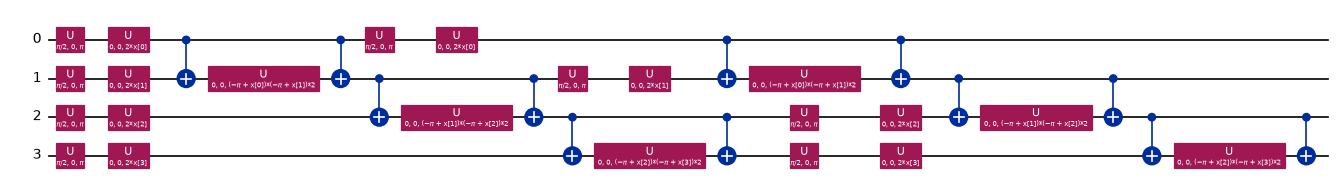

hand-made |<phi(a)|phi(b)>|^2 equals FidelityStatevectorKernel: True


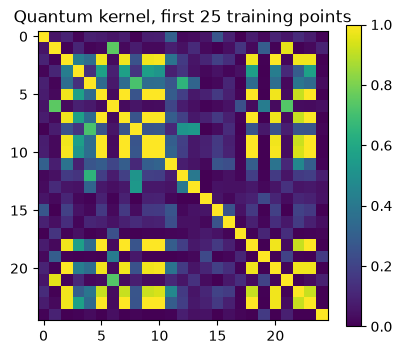

In [7]:
fm = zz_feature_map(N_QUBITS, reps=FM_REPS, entanglement="linear")        # CHOICE: feature map
display(fm.decompose().draw("mpl", fold=40, scale=0.6))

kern = FidelityStatevectorKernel(feature_map=fm)
A = P["Xq_tr"][:25]
K_qiskit = kern.evaluate(A, A)
states = [Statevector(fm.assign_parameters(a)) for a in A]
K_hand = np.array([[abs(s.inner(t)) ** 2 for t in states] for s in states])
print("hand-made |<phi(a)|phi(b)>|^2 equals FidelityStatevectorKernel:", np.allclose(K_qiskit, K_hand, atol=1e-8))
fig, ax = plt.subplots(figsize=(4.2, 3.6))
im = ax.imshow(K_qiskit, cmap="viridis", vmin=0, vmax=1); ax.set_title("Quantum kernel, first 25 training points")
plt.colorbar(im); plt.tight_layout(); plt.show()

## 4. Models, metrics and timing

Six models, exactly the paper's list. The helper `evaluate()` fits a model on the training inputs, predicts the test set and returns the paper's metrics (accuracy and class-weighted precision, recall, F1) plus the malicious-class precision / recall / F1 and the wall-clock training and testing time. `y = 1` (malicious) is the positive class in the confusion matrices.

* **SVM**: `SVC(kernel="rbf")`, scikit-learn defaults. **Decision Tree**: `criterion="gini"`. **XGBoost**: library defaults.
* **QSVM**: `QSVC(quantum_kernel=FidelityStatevectorKernel(ZZ feature map))`: the kernel matrix is computed on the state-vector simulator and handed to an SVM.
* **Pegasos QSVM**: `PegasosQSVC` with the same kernel: instead of solving the SVM dual, it takes `num_steps` stochastic sub-gradient steps, evaluating the kernel of one training point against the current support vectors at each step.
* **VQC**: `VQC` with the ZZ feature map, a `real_amplitudes` ansatz (3 repetitions) and the COBYLA optimiser on the cross-entropy loss, using a sampler with `SHOTS` shots.

In [8]:
def evaluate(name, model, Xtr, ytr, Xte, yte):
    t0 = time.perf_counter(); model.fit(Xtr, ytr); t_train = time.perf_counter() - t0
    t0 = time.perf_counter(); pred = model.predict(Xte);   t_test = time.perf_counter() - t0
    pw, rw, fw, _ = precision_recall_fscore_support(yte, pred, average="weighted", zero_division=0)
    pm, rm, fm_, _ = precision_recall_fscore_support(yte, pred, average="binary", pos_label=1, zero_division=0)
    return dict(model=name, accuracy=accuracy_score(yte, pred), precision=pw, recall=rw, f1=fw,
                mal_precision=pm, mal_recall=rm, mal_f1=fm_, train_s=t_train, test_s=t_test, pred=pred)

def classical_models(seed):
    return {"SVM": SVC(kernel="rbf", random_state=seed),
            "Decision Tree": DecisionTreeClassifier(criterion="gini", random_state=seed),
            "XGBoost": XGBClassifier(random_state=seed, n_jobs=1, verbosity=0)}

def make_fm(n): return zz_feature_map(n, reps=FM_REPS, entanglement="linear")

def make_qsvm(n):    return QSVC(quantum_kernel=FidelityStatevectorKernel(feature_map=make_fm(n)), C=QSVC_C)
def make_pegasos(n): return PegasosQSVC(quantum_kernel=FidelityStatevectorKernel(feature_map=make_fm(n)), C=PEGASOS_C, num_steps=PEGASOS_STEPS, seed=SEED)

vqc_curves = {}
def make_vqc(n, seed):
    curve = []; vqc_curves[seed] = curve
    return VQC(feature_map=make_fm(n), ansatz=real_amplitudes(n, reps=3),         # CHOICE: ansatz
               optimizer=COBYLA(maxiter=VQC_MAXITER),                              # CHOICE: optimiser
               sampler=StatevectorSampler(default_shots=SHOTS, seed=seed),
               callback=lambda w, obj: curve.append(float(obj)))

def run_seed(seed, n_qubits, with_slow=True, prep=None):
    """All six models on one seed. Returns a list of result dicts."""
    algorithm_globals.random_seed = seed; np.random.seed(seed)
    p = prep or prepare(seed, n_qubits)
    Xtr, ytr, Xte, yte = p["Xq_tr"], p["y_tr"], p["Xq_te"], p["y_te"]
    rows = []
    for nm, m in classical_models(seed).items():
        rows.append(evaluate(nm, m, Xtr, ytr, Xte, yte))
    rows.append(evaluate("QSVM", make_qsvm(n_qubits), Xtr, ytr, Xte, yte))
    if with_slow:
        rows.append(evaluate("Pegasos QSVM", make_pegasos(n_qubits), Xtr, ytr, Xte, yte))
        rows.append(evaluate("VQC", make_vqc(n_qubits, seed), Xtr, ytr, Xte, yte))
    for r in rows: r["seed"] = seed
    return rows

MODEL_ORDER = ["SVM", "Decision Tree", "XGBoost", "QSVM", "Pegasos QSVM", "VQC"]

## 5. Run all models over several seeds

Each seed redraws the 500-file sample and the split, so the spread between seeds shows how much a single 100-file test set can move the numbers. The cheap models (SVM, Decision Tree, XGBoost, QSVM) run on every seed in `SEEDS`; Pegasos QSVM and the VQC (minutes per run) run on `SLOW_SEEDS`.

In [9]:
all_rows = []
t_start = time.perf_counter()
for s in SEEDS:
    t0 = time.perf_counter()
    rows = run_seed(s, N_QUBITS, with_slow=(s in SLOW_SEEDS))
    all_rows += rows
    print(f"seed {s}: " + "  ".join(f"{r['model']}={r['accuracy']:.2f}" for r in rows) + f"   ({time.perf_counter() - t0:.0f} s)")
results = pd.DataFrame(all_rows)
print(f"total: {time.perf_counter() - t_start:.0f} s")

seed 42: SVM=0.98  Decision Tree=0.95  XGBoost=0.95  QSVM=0.94  Pegasos QSVM=0.96  VQC=0.87   (1100 s)


seed 43: SVM=0.95  Decision Tree=0.95  XGBoost=0.96  QSVM=0.91  Pegasos QSVM=0.89  VQC=0.73   (922 s)


seed 44: SVM=0.99  Decision Tree=0.99  XGBoost=0.99  QSVM=0.92  Pegasos QSVM=0.80  VQC=0.82   (1312 s)


seed 45: SVM=0.97  Decision Tree=0.95  XGBoost=0.97  QSVM=0.94   (13 s)


seed 46: SVM=0.97  Decision Tree=0.98  XGBoost=0.98  QSVM=0.91   (10 s)
total: 3355 s


In [10]:
metric_cols = ["accuracy", "precision", "recall", "f1", "mal_recall", "mal_precision", "train_s", "test_s"]
g = results.groupby("model")[metric_cols]
mean, std, cnt = g.mean().reindex(MODEL_ORDER), g.std(ddof=0).reindex(MODEL_ORDER), results.groupby("model").size().reindex(MODEL_ORDER)
std.loc[(cnt < 2).values, :] = np.nan          # a single run has no spread
summary = mean.copy()
for c in ["accuracy", "precision", "recall", "f1", "mal_recall", "mal_precision"]:
    summary[c] = [f"{100*m:.1f} +/- {100*s:.1f}" if s == s else f"{100*m:.1f} (1 run)" for m, s in zip(mean[c], std[c])]
for c in ["train_s", "test_s"]:
    summary[c] = [f"{m:.3f}" if m < 1 else f"{m:.1f}" for m in mean[c]]
summary.insert(0, "runs", cnt)
print("Test metrics in percent (class-weighted precision/recall/F1 as in the paper; mal_* = malicious class), mean +/- std over runs; times in seconds")
display(summary)

Test metrics in percent (class-weighted precision/recall/F1 as in the paper; mal_* = malicious class), mean +/- std over runs; times in seconds


,runs,accuracy,precision,recall,f1,mal_recall,mal_precision,train_s,test_s
model,,,,,,,,,
SVM,5,97.2 +/- 1.3,97.3 +/- 1.3,97.2 +/- 1.3,97.2 +/- 1.4,97.7 +/- 0.7,98.3 +/- 2.0,0.006,0.002
Decision Tree,5,96.4 +/- 1.7,96.4 +/- 1.8,96.4 +/- 1.7,96.4 +/- 1.7,97.4 +/- 1.1,97.4 +/- 1.6,0.004,0.000
XGBoost,5,97.0 +/- 1.4,97.1 +/- 1.4,97.0 +/- 1.4,97.0 +/- 1.4,98.3 +/- 1.4,97.5 +/- 1.8,0.082,0.003
QSVM,5,92.4 +/- 1.4,93.0 +/- 1.5,92.4 +/- 1.4,92.5 +/- 1.4,92.0 +/- 1.5,97.0 +/- 2.1,6.4,3.5
Pegasos QSVM,3,88.3 +/- 6.5,90.0 +/- 4.9,88.3 +/- 6.5,87.1 +/- 8.2,95.2 +/- 3.6,90.2 +/- 9.3,296.8,42.3
VQC,3,80.7 +/- 5.8,79.7 +/- 6.7,80.7 +/- 5.8,79.3 +/- 7.0,92.4 +/- 1.3,82.5 +/- 5.3,759.5,1.5


### Confusion matrices (seed 42, malicious = positive class) and the paper's Fig. 2

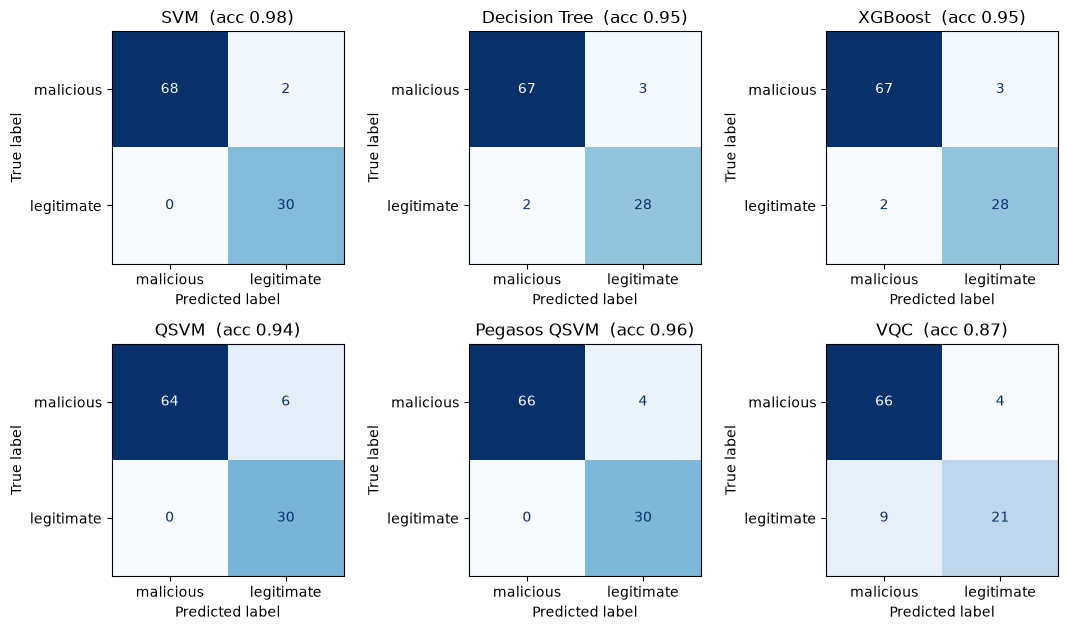

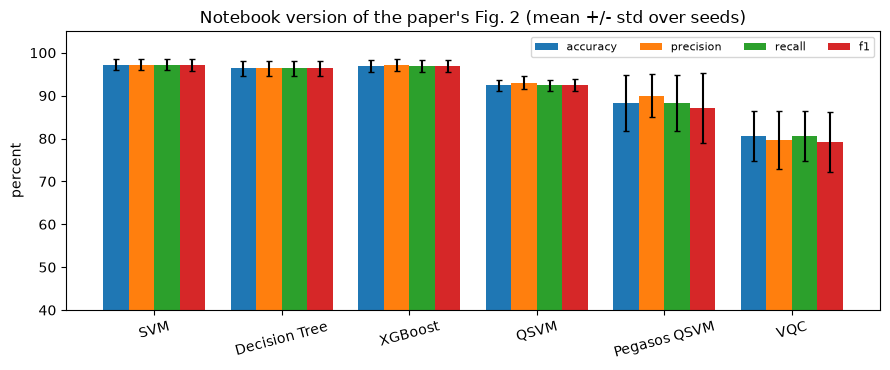

In [11]:
r42 = results[results.seed == SEED].set_index("model")
P42 = prepare(SEED, N_QUBITS)
fig, axes = plt.subplots(2, 3, figsize=(11, 6.4))
for ax, nm in zip(axes.ravel(), MODEL_ORDER):
    if nm not in r42.index: ax.axis("off"); continue
    cm = confusion_matrix(P42["y_te"], r42.loc[nm, "pred"], labels=[1, 0])
    ConfusionMatrixDisplay(cm, display_labels=["malicious", "legitimate"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"{nm}  (acc {r42.loc[nm, 'accuracy']:.2f})")
plt.tight_layout(); plt.show()

# Fig. 2 of the paper: accuracy / precision / recall / F1 for the models
fig, ax = plt.subplots(figsize=(9, 3.8))
w = 0.2
for i, c in enumerate(["accuracy", "precision", "recall", "f1"]):
    ax.bar(np.arange(6) + (i - 1.5) * w, 100 * mean[c].values, w, yerr=100 * std[c].values, capsize=2, label=c)
ax.set_xticks(range(6)); ax.set_xticklabels(MODEL_ORDER, rotation=15); ax.set_ylabel("percent"); ax.set_ylim(40, 105)
ax.set_title("Notebook version of the paper's Fig. 2 (mean +/- std over seeds)"); ax.legend(ncol=4, fontsize=8)
plt.tight_layout(); plt.show()

### Training curve of the VQC and the time comparison (paper Fig. 1)

The VQC's COBYLA objective is the cross-entropy loss. The time plot uses a log axis because the classical models take milliseconds and the simulated quantum models take seconds to minutes.

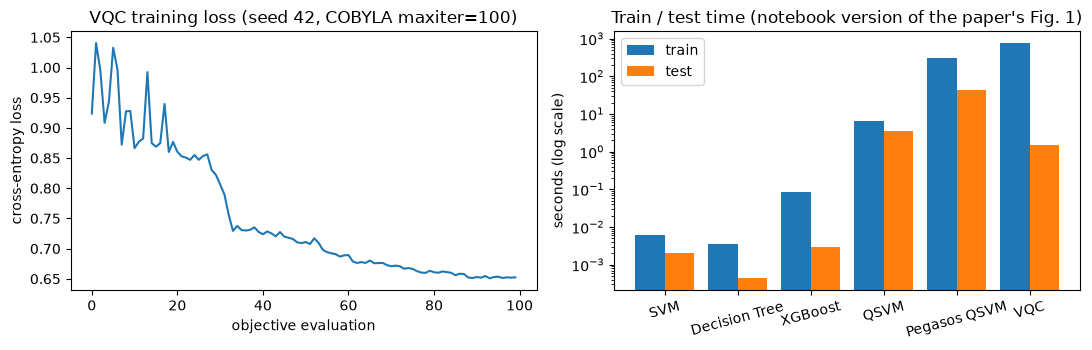

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
curve = vqc_curves.get(SEED, [])
axes[0].plot(curve); axes[0].set_xlabel("objective evaluation"); axes[0].set_ylabel("cross-entropy loss"); axes[0].set_title(f"VQC training loss (seed {SEED}, COBYLA maxiter={VQC_MAXITER})")
x = np.arange(6)
axes[1].bar(x - 0.2, mean["train_s"].values, 0.4, label="train"); axes[1].bar(x + 0.2, mean["test_s"].values, 0.4, label="test")
axes[1].set_yscale("log"); axes[1].set_xticks(x); axes[1].set_xticklabels(MODEL_ORDER, rotation=15); axes[1].set_ylabel("seconds (log scale)")
axes[1].set_title("Train / test time (notebook version of the paper's Fig. 1)"); axes[1].legend()
plt.tight_layout(); plt.show()

## 6. Does the quantum kernel help at all? A qubit sweep

The paper stresses that "the number of qubits plays a crucial role". Here the number of PCA components / qubits is varied for the SVM and the QSVM (the two kernel methods that can be rerun cheaply) on the same seeds.

accuracy    std  train_s  pca_variance
qubits model                                            
2      QSVM          0.918  0.016    6.268         0.376
       SVM (RBF)     0.968  0.015    0.005         0.376
4      QSVM          0.924  0.015    8.304         0.555
       SVM (RBF)     0.972  0.015    0.005         0.555
6      QSVM          0.928  0.025    9.076         0.662
       SVM (RBF)     0.974  0.011    0.005         0.662
8      QSVM          0.918  0.019   11.801         0.739
       SVM (RBF)     0.976  0.013    0.008         0.739

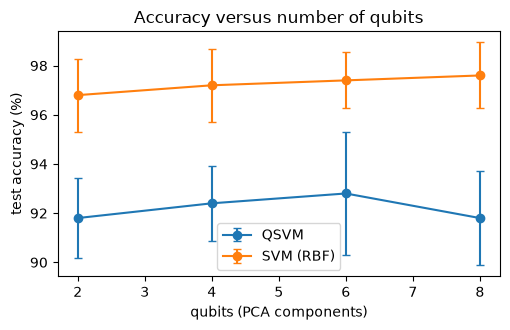

In [13]:
sweep = []
for nq in SWEEP_QUBITS:
    for s in SWEEP_SEEDS:
        p = prepare(s, nq); algorithm_globals.random_seed = s
        for nm, m in (("SVM (RBF)", SVC(kernel="rbf")), ("QSVM", make_qsvm(nq))):
            r = evaluate(nm, m, p["Xq_tr"], p["y_tr"], p["Xq_te"], p["y_te"])
            sweep.append(dict(qubits=nq, model=nm, accuracy=r["accuracy"], train_s=r["train_s"], pca_var=p["explained"]))
sw = pd.DataFrame(sweep)
tab = sw.groupby(["qubits", "model"]).agg(accuracy=("accuracy", "mean"), std=("accuracy", "std"), train_s=("train_s", "mean"), pca_variance=("pca_var", "mean")).round(3)
display(tab)
fig, ax = plt.subplots(figsize=(5.2, 3.4))
for nm, d in sw.groupby("model"):
    m = d.groupby("qubits").accuracy.agg(["mean", "std"]); ax.errorbar(m.index, 100 * m["mean"], 100 * m["std"].fillna(0), marker="o", capsize=3, label=nm)
ax.set_xlabel("qubits (PCA components)"); ax.set_ylabel("test accuracy (%)"); ax.legend(); ax.set_title("Accuracy versus number of qubits")
plt.tight_layout(); plt.show()

## 7. Diagnostics: why are the paper's classical numbers lower than ours?

The paper's classical models score 80 to 88 %, much lower than a well-prepared pipeline on this dataset can reach. The paper does not say what the classical models were fed, so four plausible inputs are compared (same seeds, same train / test split as above):

* **54 features, standardised** (classical models on all columns after `log1p` + standardisation + SMOTE),
* **54 raw features, no scaling** (what you get by calling `SVC()` straight on the table; the heavy-tailed PE sizes then dominate the RBF distance),
* **4 PCA inputs without `log1p`** (Section 2 pipeline with `LOG_TRANSFORM` off),
* **full data**: classical models trained on 80 % of all 138,047 files, evaluated on the other 20 %, to show how easy the dataset is when it is not cut to 500 files.

In [14]:
diag = []
def add(tag, nm, r): diag.append(dict(input=tag, model=nm, accuracy=r["accuracy"], f1=r["f1"]))
for s in SEEDS:
    p = prepare(s, N_QUBITS)
    for nm, m in classical_models(s).items():
        add("54 features, standardised", nm, evaluate(nm, m, p["Xa_tr"], p["ya_tr"], p["Xa_te"], p["y_te"]))
    # raw, unscaled, no SMOTE, no transform: what plain SVC() on the table does
    Xs_idx, _ = train_test_split(np.arange(len(y_all)), train_size=N_SAMPLE, stratify=y_all, random_state=s)
    Xr, yr = X_all[Xs_idx], y_all[Xs_idx]
    Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(Xr, yr, test_size=TEST_SIZE, stratify=yr, random_state=s)
    for nm, m in classical_models(s).items():
        add("54 raw features, unscaled", nm, evaluate(nm, m, Xr_tr, yr_tr, Xr_te, yr_te))
    add("majority-class baseline (always malicious)", "Dummy", evaluate("Dummy", DummyClassifier(strategy="constant", constant=1), p["Xa_tr"], p["ya_tr"], p["Xa_te"], p["y_te"]))
    pn = prepare(s, N_QUBITS, log_transform=False)
    for nm, m in classical_models(s).items():
        add("4 PCA inputs, no log1p", nm, evaluate(nm, m, pn["Xq_tr"], pn["y_tr"], pn["Xq_te"], pn["y_te"]))
    pn_q = evaluate("QSVM", make_qsvm(N_QUBITS), pn["Xq_tr"], pn["y_tr"], pn["Xq_te"], pn["y_te"])
    add("4 PCA inputs, no log1p", "QSVM", pn_q)
# full data, one seed (classical only)
Xf_tr, Xf_te, yf_tr, yf_te = train_test_split(X_all, y_all, test_size=TEST_SIZE, stratify=y_all, random_state=SEED)
for nm, m in classical_models(SEED).items():
    if nm == "SVM":                       # SVC on 110k points is slow: use 20,000 training points, standardised
        sc_f = StandardScaler().fit(signed_log1p(Xf_tr[:20000]));
        r = evaluate(nm, m, sc_f.transform(signed_log1p(Xf_tr[:20000])), yf_tr[:20000], sc_f.transform(signed_log1p(Xf_te)), yf_te)
    else:
        r = evaluate(nm, m, Xf_tr, yf_tr, Xf_te, yf_te)
    add("full data (110k train; SVM 20k)", nm, r)
dg = pd.DataFrame(diag).groupby(["input", "model"]).agg(accuracy=("accuracy", "mean"), std=("accuracy", "std"), f1=("f1", "mean")).round(3)
display(dg)

accuracy    std  \
input                                      model                            
4 PCA inputs, no log1p                     Decision Tree     0.956  0.015   
                                           QSVM              0.922  0.024   
                                           SVM               0.964  0.026   
                                           XGBoost           0.964  0.021   
54 features, standardised                  Decision Tree     0.962  0.013   
                                           SVM               0.978  0.013   
                                           XGBoost           0.972  0.008   
54 raw features, unscaled                  Decision Tree     0.964  0.011   
                                           SVM               0.768  0.029   
                                           XGBoost           0.978  0.013   
full data (110k train; SVM 20k)            Decision Tree     0.993    NaN   
                                           SVM               0.991    NaN   
                                           XGBoost           0.996    NaN   
majority-class baseline (always malicious) Dummy             0.700  0.000   

                                                             f1  
input                                      model                 
4 PCA inputs, no log1p                     Decision Tree  0.956  
                                           QSVM           0.923  
                                           SVM            0.964  
                                           XGBoost        0.964  
54 features, standardised                  Decision Tree  0.962  
                                           SVM            0.978  
                                           XGBoost        0.972  
54 raw features, unscaled                  Decision Tree  0.964  
                                           SVM            0.709  
                                           XGBoost        0.978  
full data (110k train; SVM 20k)            Decision Tree  0.993  
                                           SVM            0.991  
                                           XGBoost        0.996  
majority-class baseline (always malicious) Dummy          0.576

## 8. Side by side with the paper

Paper values come from Tables III and IV. A numeric claim is **reproduced** when the notebook mean is within 2 accuracy points (0.02 for F1 and for the other metrics) of the paper's number, **not reached** when the notebook is lower by more, **exceeded** when it is higher by more. Times are machine and implementation dependent (the paper's quantum times reflect Qiskit's sampler-based simulation); they are only judged by their order of magnitude and ordering.

In [15]:
paper = {  # Table III (percent) and Table IV (seconds)
    "SVM":           dict(accuracy=80, precision=82, recall=80, f1=81, train_s=0.023,  test_s=0.038),
    "Decision Tree": dict(accuracy=88, precision=88, recall=88, f1=88, train_s=0.023,  test_s=0.025),
    "XGBoost":       dict(accuracy=88, precision=88, recall=88, f1=88, train_s=0.358,  test_s=0.024),
    "QSVM":          dict(accuracy=68, precision=74, recall=68, f1=70, train_s=1088.2, test_s=436.2),
    "Pegasos QSVM":  dict(accuracy=75, precision=72, recall=75, f1=71, train_s=3481.6, test_s=400.9),
    "VQC":           dict(accuracy=57, precision=63, recall=57, f1=59, train_s=705.9,  test_s=1.1),
}
def verdict(p, n, tol=2.0):
    d = n - p
    return "reproduced" if abs(d) <= tol else ("exceeded" if d > 0 else "not reached")
rows = []
for nm in MODEL_ORDER:
    for met in ["accuracy", "precision", "recall", "f1"]:
        n = 100 * mean.loc[nm, met]; sd = 100 * std.loc[nm, met]
        rows.append(dict(model=nm, metric=met, paper=paper[nm][met], notebook=round(n, 1), std=round(sd, 1),
                         gap=round(n - paper[nm][met], 1), verdict=verdict(paper[nm][met], n)))
cmp_df = pd.DataFrame(rows)
display(cmp_df.pivot(index="model", columns="metric", values="notebook").reindex(MODEL_ORDER)[["accuracy", "precision", "recall", "f1"]].assign(source="notebook").round(1))
display(cmp_df[cmp_df.metric.isin(["accuracy", "f1"])].reset_index(drop=True))
print("Counts of verdicts (accuracy, precision, recall, F1 for the six models):\n", cmp_df.verdict.value_counts().to_string())

metric,accuracy,precision,recall,f1,source
model,,,,,
SVM,97.2,97.3,97.2,97.2,notebook
Decision Tree,96.4,96.4,96.4,96.4,notebook
XGBoost,97.0,97.1,97.0,97.0,notebook
QSVM,92.4,93.0,92.4,92.5,notebook
Pegasos QSVM,88.3,90.0,88.3,87.1,notebook
VQC,80.7,79.7,80.7,79.3,notebook


,model,metric,paper,notebook,std,gap,verdict
0,SVM,accuracy,80,97.2,1.3,17.2,exceeded
1,SVM,f1,81,97.2,1.4,16.2,exceeded
2,Decision Tree,accuracy,88,96.4,1.7,8.4,exceeded
3,Decision Tree,f1,88,96.4,1.7,8.4,exceeded
4,XGBoost,accuracy,88,97.0,1.4,9.0,exceeded
5,XGBoost,f1,88,97.0,1.4,9.0,exceeded
6,QSVM,accuracy,68,92.4,1.4,24.4,exceeded
7,QSVM,f1,70,92.5,1.4,22.5,exceeded
8,Pegasos QSVM,accuracy,75,88.3,6.5,13.3,exceeded
9,Pegasos QSVM,f1,71,87.1,8.2,16.1,exceeded


Counts of verdicts (accuracy, precision, recall, F1 for the six models):
 verdict
exceeded    24


In [16]:
# Qualitative claims of the paper, each checked on the notebook's means.
# To compare models fairly, use only the seeds on which all six models were run.
cm = results[results.seed.isin(SLOW_SEEDS)].groupby("model")[["accuracy", "precision", "recall", "f1", "train_s", "test_s"]].mean().reindex(MODEL_ORDER)
print("Claims are checked on seeds", SLOW_SEEDS, "(all six models present)")
a = {m: 100 * cm.loc[m, "accuracy"] for m in MODEL_ORDER}
p_ = {m: 100 * cm.loc[m, "precision"] for m in MODEL_ORDER}
tr = {m: cm.loc[m, "train_s"] for m in MODEL_ORDER}; te = {m: cm.loc[m, "test_s"] for m in MODEL_ORDER}
q = ["QSVM", "Pegasos QSVM", "VQC"]; cl = ["SVM", "Decision Tree", "XGBoost"]
dt_xgb_same = max(abs(cm.loc["Decision Tree", c] - cm.loc["XGBoost", c]) for c in ["accuracy", "precision", "recall", "f1"]) <= 0.01
claims = [
 ("Decision Tree and XGBoost beat the classical SVM (88 vs 80)", a["Decision Tree"] > a["SVM"] and a["XGBoost"] > a["SVM"], f"DT {a['Decision Tree']:.1f}, XGB {a['XGBoost']:.1f}, SVM {a['SVM']:.1f}"),
 ("Decision Tree and XGBoost give identical metrics (88/88/88/88)", dt_xgb_same, f"DT {a['Decision Tree']:.1f} vs XGB {a['XGBoost']:.1f}"),
 ("Pegasos QSVM is the most accurate quantum model", max(q, key=a.get) == "Pegasos QSVM", ", ".join(f"{m} {a[m]:.1f}" for m in q)),
 ("VQC is the weakest model overall (57 %)", min(MODEL_ORDER, key=a.get) == "VQC", f"lowest: {min(MODEL_ORDER, key=a.get)} {min(a.values()):.1f}"),
 ("The quantum models did not outperform the classical ones", max(a[m] for m in q) <= max(a[m] for m in cl), f"best quantum {max(a[m] for m in q):.1f} vs best classical {max(a[m] for m in cl):.1f}"),
 ("QSVM outperforms the classical SVM in precision (text; Table III says 74 < 82)", p_["QSVM"] > p_["SVM"], f"QSVM {p_['QSVM']:.1f} vs SVM {p_['SVM']:.1f}"),
 ("Quantum models need far more training time than classical ones (paper: 3 orders of magnitude; here: >= 10x)", min(tr[m] for m in q) >= 10 * max(tr[m] for m in cl), f"quantum {min(tr[m] for m in q):.2f}-{max(tr[m] for m in q):.1f} s vs classical <= {max(tr[m] for m in cl):.3f} s"),
 ("Pegasos QSVM has the longest training time of the quantum models", max(q, key=tr.get) == "Pegasos QSVM", ", ".join(f"{m} {tr[m]:.1f}s" for m in q)),
 ("VQC has the shortest test time of the quantum models (1.1 s)", min(q, key=te.get) == "VQC", ", ".join(f"{m} {te[m]:.2f}s" for m in q)),
 ("VQC has the shortest training time of the quantum models (705.9 s vs 1088 / 3482)", min(q, key=tr.get) == "VQC", ", ".join(f"{m} {tr[m]:.1f}s" for m in q)),
]
cl_df = pd.DataFrame([dict(claim=c, verdict="reproduced" if ok else "not reached here", evidence=ev) for c, ok, ev in claims])
pd.set_option("display.max_colwidth", 120); display(cl_df)

Claims are checked on seeds [42, 43, 44] (all six models present)


,claim,verdict,evidence
0,Decision Tree and XGBoost beat the classical SVM (88 vs 80),not reached here,"DT 96.3, XGB 96.7, SVM 97.3"
1,Decision Tree and XGBoost give identical metrics (88/88/88/88),reproduced,DT 96.3 vs XGB 96.7
2,Pegasos QSVM is the most accurate quantum model,not reached here,"QSVM 92.3, Pegasos QSVM 88.3, VQC 80.7"
3,VQC is the weakest model overall (57 %),reproduced,lowest: VQC 80.7
4,The quantum models did not outperform the classical ones,reproduced,best quantum 92.3 vs best classical 97.3
5,QSVM outperforms the classical SVM in precision (text; Table III says 74 < 82),not reached here,QSVM 93.2 vs SVM 97.4
6,Quantum models need far more training time than classical ones (paper: 3 orders of magnitude; here: >= 10x),reproduced,quantum 6.61-759.5 s vs classical <= 0.084 s
7,Pegasos QSVM has the longest training time of the quantum models,not reached here,"QSVM 6.6s, Pegasos QSVM 296.8s, VQC 759.5s"
8,VQC has the shortest test time of the quantum models (1.1 s),reproduced,"QSVM 3.12s, Pegasos QSVM 42.33s, VQC 1.46s"
9,VQC has the shortest training time of the quantum models (705.9 s vs 1088 / 3482),not reached here,"QSVM 6.6s, Pegasos QSVM 296.8s, VQC 759.5s"


In [17]:
# Data statements of the paper
checks = pd.DataFrame([
    ("138,047 samples, 57 columns", f"{raw.shape[0]:,} x {raw.shape[1]}", raw.shape == (138047, 57)),
    ("41,323 vs 96,724 files (Table II)", f"{int(vc[1]):,} legitimate / {int(vc[0]):,} malicious", (int(vc[1]), int(vc[0])) == (41323, 96724)),
    ("70 % malicious", f"{vc[0] / len(raw):.1%}", abs(vc[0] / len(raw) - 0.70) < 0.01),
    ("54 independent variables after removing Name, md5, target", str(len(feature_names)), len(feature_names) == 54),
    ("The first 500 entries contain both classes (needed for any experiment)", str(first500), len(first500) > 1),
], columns=["statement", "notebook", "holds"])
checks["verdict"] = np.where(checks.holds, "reproduced", "cannot be followed / contradicted")
display(checks.drop(columns="holds"))

,statement,notebook,verdict
0,"138,047 samples, 57 columns","138,047 x 57",reproduced
1,"41,323 vs 96,724 files (Table II)","41,323 legitimate / 96,724 malicious",reproduced
2,70 % malicious,70.1%,reproduced
3,"54 independent variables after removing Name, md5, target",54,reproduced
4,The first 500 entries contain both classes (needed for any experiment),{1: 500},cannot be followed / contradicted


## 9. Reading the paper critically

* **Not a ransomware dataset.** The table is a generic Windows PE-header malware set: legitimate binaries versus VirusShare malware of any family. Nothing in it identifies ransomware, so the paper's title and conclusions about "ransomware detection" are really about malware detection from header fields.
* **The class names are swapped and the "first 500" cannot be used.** Table II calls the 41,323 files "Ransomware" while the file (and the 70 % statement) says they are the legitimate ones; and the first 500 rows are all of one class. How the authors actually obtained two classes in 500 rows is unknown, so the exact test set cannot be recovered.
* **A 100-file (or smaller) test set.** One flipped file moves accuracy by one point, and the std over seeds above shows the spread to be several points. Differences like 75 versus 68 % between Pegasos QSVM and QSVM are within that noise.
* **Weak classical baselines.** On the same table our classical models reach 96 to 97 % on the 4 quantum inputs (and above 99 % when trained on the full data), far above the paper's 80 to 88 %. The unscaled-feature diagnostic in Section 7 shows how easily an RBF SVM falls to roughly 77 % when the heavy-tailed PE sizes are fed in raw, so the paper's low classical numbers probably come from preprocessing rather than from the data. The paper's conclusion "quantum is not better than classical" survives, but the size of the gaps (about 20 points for the SVM) does not.
* **The quantum numbers are the product of unspecified choices.** Qubit count, feature map, ansatz, optimiser, `C` and number of Pegasos steps are not given. A test set with the dataset's 70 / 30 class ratio gives 70 % accuracy to a predictor that always says "malicious" (the majority-class row in Section 7), so the paper's VQC at 57 % would be worse than a constant predictor, a possibility the weighted-average metrics hide. Our VQC (about 80 %) is above that bar, but far below the kernel methods.
* **Internal inconsistencies.** The text claims that QSVM beats the SVM in precision, but Table III has 74 versus 82; it gives the QSVC accuracy as 68.5 % where Table III says 68 %; and the conclusion calls Pegasos QSVM the most accurate quantum model while Table III has it 7 points above QSVM on a test set that is probably 100 files or fewer. Feature-selection steps (VIF, IV, WoE) are described, but the surviving features and the PCA dimension are not reported.
* **Time comparison.** Simulating a quantum kernel on a CPU measures the cost of simulation, not of quantum hardware. The paper's absolute quantum times (hundreds to thousands of seconds) depend on the Qiskit primitive used; in this notebook the exact state-vector kernel is far faster than a sampler-based one, while the VQC (many circuit executions per optimiser step) is the slow one.
* **Single run, no variance, no tuning.** None of the models is tuned and there is one run, so the ranking of the models is not statistically supported.

## 10. Exercises

1. **Majority-class baseline.** Section 7 contains an always-"malicious" predictor. Compare its accuracy and weighted F1 with the VQC over all seeds in the full run. By how many points does the VQC beat it, and is that difference larger than the std over seeds?
2. **Pegasos steps.** Sweep `PEGASOS_STEPS` over 50, 200, 1000, 3000 and plot accuracy and training time. When does Pegasos match the exact `QSVC`?
3. **Feature map.** Replace `zz_feature_map` by `z_feature_map` (no entanglement) and by `pauli_feature_map(paulis=["Z","YY"])`. Does the entangling kernel help here, and at what cost in time?
4. **Kernel bandwidth.** Multiply the PCA angles by a factor in {0.25, 0.5, 1, 2} before the feature map and choose the factor on a validation split of the training data. Report the test accuracy of the chosen QSVM.
5. **Honest sample size.** Re-run Section 5 with `N_SAMPLE` in {200, 500, 2000, 5000}. How many files does the QSVM need to match the classical SVM on the same inputs, and what happens to the kernel computation time?